In [11]:
!pip install seaborn


[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


(3000, 11)
Missing values: 0


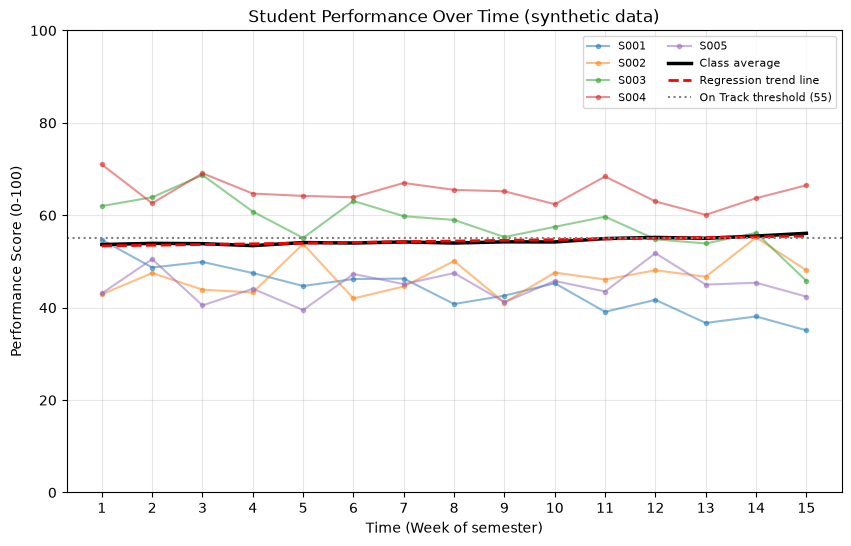

Trend: score changes by about 0.15 points per week on average


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("student_performance_timeseries.csv")
print(df.shape)
print("Missing values:", df.isnull().sum().sum())

avg = df.groupby("week")["performance_score"].mean()
slope, intercept = np.polyfit(df["week"], df["performance_score"], 1)

plt.figure(figsize=(10, 6))
for sid in ["S001", "S002", "S003", "S004", "S005"]:
    d = df[df["student_id"] == sid]
    plt.plot(d["week"], d["performance_score"], marker="o", markersize=3, alpha=0.5, label=sid)
plt.plot(avg.index, avg.values, color="black", linewidth=2.5, label="Class average")
plt.plot(avg.index, slope * avg.index + intercept, "r--", linewidth=2, label="Regression trend line")
plt.axhline(55, color="gray", linestyle=":", label="On Track threshold (55)")
plt.xlabel("Time (Week of semester)")
plt.ylabel("Performance Score (0-100)")
plt.title("Student Performance Over Time (synthetic data)")
plt.xticks(range(1, 16))
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.legend(ncol=2, fontsize=8)
plt.show()

print(f"Trend: score changes by about {slope:.2f} points per week on average")

Linear Regression: R2 = 0.947 | MAE = 2.12 | RMSE = 2.69
Random Forest Regressor: R2 = 0.933 | MAE = 2.38 | RMSE = 3.03


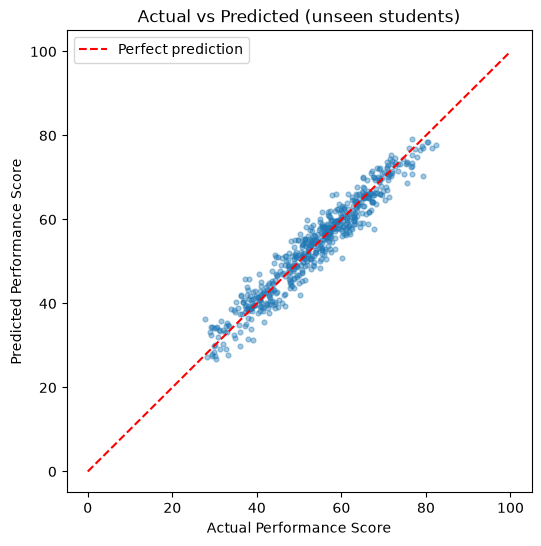

Saved model/student_regressor.joblib and model/regression_metrics.json


In [10]:
import json, joblib
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

FEATURES = ["week", "attendance", "study_hours", "previous_marks",
            "assignment_completion", "internal_marks", "failed_subjects", "sleep_hours"]
X, y = df[FEATURES], df["performance_score"]

# 80:20 split, keeping each student entirely in train or entirely in test
train_idx, test_idx = next(GroupShuffleSplit(test_size=0.2, random_state=42)
                           .split(X, y, groups=df["student_id"]))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42),
}

results = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    results[name] = {"R2": r2_score(y_test, p),
                     "MAE": mean_absolute_error(y_test, p),
                     "RMSE": mean_squared_error(y_test, p) ** 0.5}
    print(f"{name}: R2 = {results[name]['R2']:.3f} | MAE = {results[name]['MAE']:.2f} | RMSE = {results[name]['RMSE']:.2f}")

# Graph: actual vs predicted on unseen students (Random Forest)
rf = models["Random Forest Regressor"]
pred = rf.predict(X_test)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.4, s=12)
plt.plot([0, 100], [0, 100], "r--", label="Perfect prediction")
plt.xlabel("Actual Performance Score")
plt.ylabel("Predicted Performance Score")
plt.title("Actual vs Predicted (unseen students)")
plt.legend()
plt.show()

joblib.dump(rf, "student_regressor.joblib")
with open("regression_metrics.json", "w") as f:
    json.dump(results, f, indent=2)
print("Saved model/student_regressor.joblib and model/regression_metrics.json")

In [7]:
%%writefile app.py
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import streamlit as st

BASE = Path(__file__).parent
MODEL_PATH = BASE / "student_regressor.joblib"
METRICS_PATH = BASE / "regression_metrics.json"
DATA_PATH = BASE / "student_performance_timeseries.csv"

THRESHOLD = 55          # score at or above this = On Track
MODEL_NAME = "Random Forest Regressor"

st.set_page_config(page_title="Student Performance Predictor", page_icon="🎓", layout="centered")

INPUT_KEYS = ["week", "attendance", "study_hours", "previous_marks",
              "assignment_completion", "internal_marks", "failed_subjects", "sleep_hours"]

LIMITS = {
    "week": ("Week of Semester", 1, 15),
    "attendance": ("Attendance Percentage", 0, 100),
    "study_hours": ("Average Study Hours Per Day", 0, 12),
    "previous_marks": ("Previous Examination Marks", 0, 100),
    "assignment_completion": ("Assignment Completion Percentage", 0, 100),
    "internal_marks": ("Internal Assessment Marks", 0, 100),
    "failed_subjects": ("Number of Previous Failed Subjects", 0, 10),
    "sleep_hours": ("Average Daily Sleep Hours", 0, 12),
}


@st.cache_resource
def load_model():
    return joblib.load(MODEL_PATH)


@st.cache_data
def load_metrics():
    with open(METRICS_PATH) as f:
        return json.load(f)


@st.cache_data
def load_data():
    return pd.read_csv(DATA_PATH)


def clear_inputs():
    for key in INPUT_KEYS:
        st.session_state[key] = None
    st.session_state["student_name"] = ""


def validate(name, values):
    """Return a list of error messages (empty list means all good)."""
    errors = []
    if not name.strip():
        errors.append("Please enter the Student ID or Name.")
    for key, (label, low, high) in LIMITS.items():
        value = values[key]
        if value is None:
            if key != "sleep_hours":          # sleep is optional
                errors.append(f"{label} is required.")
        elif value < low or value > high:
            errors.append(f"{label} must be between {low} and {high}.")
    return errors


def recommendations(v, needs_support):
    """Pick three supportive suggestions based on the entered values."""
    recs = []
    if v["attendance"] < 75:
        recs.append("Try to attend classes more regularly. Aim for at least 75% attendance, since class discussions make revision easier.")
    if v["study_hours"] < 2:
        recs.append("Create a simple daily timetable with 2 to 3 focused study hours, split into short sessions with breaks.")
    if v["assignment_completion"] < 70:
        recs.append("Complete and submit assignments on time. Breaking each one into small daily tasks can make this manageable.")
    if v["previous_marks"] < 50 or v["internal_marks"] < 50:
        recs.append("Identify the topics that were hardest in previous tests and ask your teacher for help with those first.")
    if v["failed_subjects"] >= 1:
        recs.append("Speak with your academic advisor about a plan to clear earlier backlogs step by step.")
    if v["sleep_hours"] is not None and v["sleep_hours"] < 6:
        recs.append("Aim for 7 to 8 hours of sleep. Good rest improves concentration and memory.")
    if needs_support:
        recs.append("Consider meeting a mentor or academic counsellor. Asking for guidance early is a strong and sensible step.")
    general = [
        "Keep up your current habits and review your progress every week.",
        "Form a small study group so you can explain topics to each other.",
        "Practise with past question papers to build confidence for exams.",
    ]
    return (recs + general)[:3]


def predict_score(model, values):
    row = pd.DataFrame([values])[list(model.feature_names_in_)]
    return float(np.clip(model.predict(row)[0], 0, 100))


# ------------------------------------------------------------------ PAGE
st.title("🎓 AI-Based Student Performance Predictor")
st.write("Enter a student's details to get an **estimated performance score (0-100)** from a "
         "Random Forest regression model, and see how the estimate looks over the semester.")

if not MODEL_PATH.exists():
    st.error("Model file 'model/student_regressor.joblib' was not found. Please run Cell B in the "
             "Jupyter Notebook first, and make sure app.py is in the same folder as the 'model' folder.")
    st.stop()

model = load_model()
tab_predict, tab_time, tab_info = st.tabs(["📝 Predict", "📈 Performance Over Time", "📊 Model Information"])

# ------------------------------------------------------------------ PREDICT
with tab_predict:
    with st.form("student_form"):
        name = st.text_input("Student ID or Name", key="student_name",
                             help="Used only to label this result. It is not used by the model.")
        c1, c2 = st.columns(2)
        with c1:
            week = st.number_input("Week of Semester (1-15)", 1, 15, value=None, step=1,
                                   key="week", placeholder="e.g. 8")
            attendance = st.number_input("Attendance Percentage (0-100)", 0.0, 100.0,
                                         value=None, step=1.0, key="attendance", placeholder="e.g. 82")
            previous_marks = st.number_input("Previous Examination Marks % (0-100)", 0.0, 100.0,
                                             value=None, step=1.0, key="previous_marks", placeholder="e.g. 68")
            internal_marks = st.number_input("Internal Assessment Marks % (0-100)", 0.0, 100.0,
                                             value=None, step=1.0, key="internal_marks", placeholder="e.g. 70")
        with c2:
            study_hours = st.number_input("Average Study Hours Per Day (0-12)", 0.0, 12.0,
                                          value=None, step=0.5, key="study_hours", placeholder="e.g. 3.5")
            assignment_completion = st.number_input("Assignment Completion % (0-100)", 0.0, 100.0,
                                                    value=None, step=1.0, key="assignment_completion", placeholder="e.g. 90")
            failed_subjects = st.number_input("Previous Failed Subjects (0-10)", 0, 10,
                                              value=None, step=1, key="failed_subjects", placeholder="e.g. 0")
            sleep_hours = st.number_input("Average Daily Sleep Hours (0-12, optional)", 0.0, 12.0,
                                          value=None, step=0.5, key="sleep_hours", placeholder="optional, default 7")

        b1, b2 = st.columns(2)
        predict_clicked = b1.form_submit_button("Predict Performance", type="primary", use_container_width=True)
        b2.form_submit_button("Clear Inputs", on_click=clear_inputs, use_container_width=True)

    if predict_clicked:
        values = {
            "week": week, "attendance": attendance, "study_hours": study_hours,
            "previous_marks": previous_marks, "assignment_completion": assignment_completion,
            "internal_marks": internal_marks, "failed_subjects": failed_subjects,
            "sleep_hours": sleep_hours,
        }
        errors = validate(name, values)
        if errors:
            for e in errors:
                st.error(e)
        else:
            try:
                note = None
                if values["sleep_hours"] is None:
                    values["sleep_hours"] = 7.0
                    note = "Sleep hours were not entered, so 7.0 hours was assumed."

                score = predict_score(model, values)
                needs_support = score < THRESHOLD
                label = "Needs Support" if needs_support else "On Track"

                # typical error from the saved evaluation (if available)
                mae = None
                if METRICS_PATH.exists():
                    mae = load_metrics().get(MODEL_NAME, {}).get("MAE")

                st.divider()
                st.subheader("Prediction Result")
                st.write(f"**Student:** {name.strip()}  |  **Week:** {int(values['week'])}")
                st.metric("Predicted Performance Score", f"{score:.1f} / 100")
                if needs_support:
                    st.warning(f"Category: **{label}** (score below {THRESHOLD})")
                else:
                    st.success(f"Category: **{label}** (score {THRESHOLD} or above)")
                st.progress(min(max(score / 100, 0.0), 1.0))
                if mae is not None:
                    st.caption(f"On unseen test students, this model's typical error was about "
                               f"±{mae:.1f} points, so treat the score as an estimate, not a guarantee.")
                else:
                    st.caption("This score is an estimate, not a guarantee of any academic outcome.")
                if note:
                    st.info(note)

                # ---- graph: X = week, Y = predicted score
                weeks = list(range(1, 16))
                proj = [predict_score(model, {**values, "week": w}) for w in weeks]
                fig, ax = plt.subplots(figsize=(8, 4.5))
                ax.plot(weeks, proj, marker="o", color="#1f77b4",
                        label="Predicted score (entered values kept constant)")
                ax.scatter([values["week"]], [score], color="red", s=90, zorder=5,
                           label=f"Selected week ({int(values['week'])})")
                if DATA_PATH.exists():
                    avg = load_data().groupby("week")["performance_score"].mean()
                    ax.plot(avg.index, avg.values, color="black", linestyle="--", label="Class average (dataset)")
                ax.axhline(THRESHOLD, color="gray", linestyle=":", label=f"On Track threshold ({THRESHOLD})")
                ax.set_xlabel("Time (Week of semester)")
                ax.set_ylabel("Performance Score (0-100)")
                ax.set_title("Predicted Performance Over Time")
                ax.set_xticks(weeks)
                ax.set_ylim(0, 100)
                ax.grid(alpha=0.3)
                ax.legend(fontsize=8)
                st.pyplot(fig)
                plt.close(fig)
                st.caption("The line shows what the model predicts if these same habits continued every week. "
                           "It is a what-if view, not a forecast of real events.")

                st.markdown("**Summary of entered information**")
                summary = pd.DataFrame({
                    "Item": [LIMITS[k][0] for k in INPUT_KEYS],
                    "Value": [str(values[k]) for k in INPUT_KEYS],
                })
                st.table(summary)

                st.markdown("**Three supportive suggestions**")
                for i, r in enumerate(recommendations(values, needs_support), start=1):
                    st.write(f"{i}. {r}")

                st.info("⚠️ Disclaimer: This is an estimate made by a Machine Learning model trained on "
                        "synthetic (artificial) data. It is not a permanent label and should not be used "
                        "for real academic decisions.")
            except Exception as err:
                st.error(f"Something went wrong while predicting: {err}")

# ------------------------------------------------------- PERFORMANCE OVER TIME
with tab_time:
    st.subheader("Performance Over Time (training dataset)")
    if DATA_PATH.exists():
        data = load_data()
        avg = data.groupby("week")["performance_score"].mean()
        slope, intercept = np.polyfit(data["week"], data["performance_score"], 1)

        fig, ax = plt.subplots(figsize=(8, 4.5))
        for sid in data["student_id"].unique()[:5]:
            d = data[data["student_id"] == sid]
            ax.plot(d["week"], d["performance_score"], marker="o", markersize=3, alpha=0.5, label=sid)
        ax.plot(avg.index, avg.values, color="black", linewidth=2.5, label="Class average")
        ax.plot(avg.index, slope * avg.index + intercept, "r--", linewidth=2, label="Regression trend line")
        ax.axhline(THRESHOLD, color="gray", linestyle=":", label=f"On Track threshold ({THRESHOLD})")
        ax.set_xlabel("Time (Week of semester)")
        ax.set_ylabel("Performance Score (0-100)")
        ax.set_xticks(range(1, 16))
        ax.set_ylim(0, 100)
        ax.grid(alpha=0.3)
        ax.legend(ncol=2, fontsize=8)
        st.pyplot(fig)
        plt.close(fig)
        st.write(f"Trend line: the average score changes by about **{slope:.2f} points per week**.")
        st.caption("This dataset is synthetic (artificially generated), so this graph shows the demo data, not real students.")
    else:
        st.warning("Dataset file 'data/student_performance_timeseries.csv' was not found.")

# --------------------------------------------------------------- MODEL INFO
with tab_info:
    st.subheader("About the Model")
    st.write("**Task:** Regression (predicts a number from 0 to 100).")
    st.write(f"**Algorithm used by this website:** {MODEL_NAME} (Scikit-learn), a group of decision trees whose predictions are averaged.")
    st.write("**Input features:** " + ", ".join(model.feature_names_in_))
    st.write("**Not used as a feature:** student name or ID.")
    st.write(f"**Category rule:** score of {THRESHOLD} or above = On Track, otherwise Needs Support.")
    st.write("**Training process:** the data was split 80% for training and 20% for testing. "
             "The split was done by student, so test students were never seen during training.")

    if METRICS_PATH.exists():
        m = load_metrics()
        st.markdown("**Evaluation on unseen test students**")
        rows = []
        for model_label, res in m.items():
            rows.append({"Model": model_label,
                         "R2": round(res["R2"], 3),
                         "MAE": round(res["MAE"], 2),
                         "RMSE": round(res["RMSE"], 2)})
        st.table(pd.DataFrame(rows))
        st.caption("R2: closer to 1 is better. MAE and RMSE: average error in score points, lower is better.")
    else:
        st.warning("regression_metrics.json not found. Run Cell B in the notebook to create it.")

    if hasattr(model, "feature_importances_"):
        st.markdown("**Feature importance**")
        imp = pd.Series(model.feature_importances_, index=model.feature_names_in_).sort_values()
        st.bar_chart(imp)

    st.markdown("**Important limitations**")
    st.write("- The data is **synthetic**. Scores came from an assumed formula plus random noise, not real student results.")
    st.write("- Good metrics here only show the model learned that formula. They do **not** prove real-world accuracy.")
    st.write("- Only a few factors are used. Many real influences (health, family situation, teaching quality) are missing.")
    st.write("- Predictions are estimates and should never be treated as guaranteed outcomes.")

Overwriting app.py


In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("charts", exist_ok=True)
os.makedirs("model", exist_ok=True)
sns.set_theme(style="whitegrid")

raw = pd.read_csv("student_performance_raw.csv")
print("Shape:", raw.shape)
print(raw.head())
raw.info()
print(raw.describe().round(2))
print("\nMissing values:\n", raw.isnull().sum())
print("\nDuplicate rows:", raw.duplicated().sum())

Shape: (3030, 14)
  student_id  week      year study_mode motivation_level  attendance  \
0       S001     1  3rd Year   Coaching           Medium        70.5   
1       S001     2  3rd Year   Coaching           Medium        66.7   
2       S001     3  3rd Year   Coaching           Medium        68.4   
3       S001     4  3rd Year   Coaching           Medium        63.4   
4       S001     5  3rd Year   Coaching           Medium        62.5   

   study_hours  previous_marks  assignment_completion  internal_marks  \
0          4.3            57.4                   72.0            61.2   
1          3.0            57.4                   74.9            56.8   
2          3.2            57.4                   65.1            55.1   
3          3.4            57.4                   78.6            52.0   
4          3.6            57.4                   63.1            50.4   

   failed_subjects  sleep_hours  performance_score performance_category  
0                1          6.9     

In [5]:
df = raw.copy()

# 1. Remove duplicate rows
df = df.drop_duplicates()

# 2. Fix inconsistent text (extra spaces, capital letters)
for col in ["study_mode", "motivation_level"]:
    df[col] = df[col].astype("string").str.strip().str.capitalize()

# 3. Mark impossible values as missing
num_cols = ["attendance", "study_hours", "previous_marks", "assignment_completion",
            "internal_marks", "failed_subjects", "sleep_hours"]
limits = {"attendance": (0, 100), "study_hours": (0, 12), "previous_marks": (0, 100),
          "assignment_completion": (0, 100), "internal_marks": (0, 100),
          "failed_subjects": (0, 10), "sleep_hours": (0, 12)}
for c, (lo, hi) in limits.items():
    bad = (df[c] < lo) | (df[c] > hi)
    print(c, "out of range:", int(bad.sum()))
    df.loc[bad, c] = np.nan

# 4. Fill missing values: median for numbers, most common value for text
for c in num_cols:
    df[c] = df[c].fillna(df[c].median())
for c in ["study_mode", "motivation_level", "year"]:
    df[c] = df[c].fillna(df[c].mode()[0])

print("\nMissing values after cleaning:", int(df.isnull().sum().sum()))
print("Rows after cleaning:", len(df))
df.to_csv("data/student_cleaned.csv", index=False)
print(df["study_mode"].value_counts())

attendance out of range: 4
study_hours out of range: 4
previous_marks out of range: 0
assignment_completion out of range: 0
internal_marks out of range: 0
failed_subjects out of range: 0
sleep_hours out of range: 0

Missing values after cleaning: 0
Rows after cleaning: 3000
study_mode
Self-study     1382
Group study     970
Coaching        648
Name: count, dtype: int64[pyarrow]


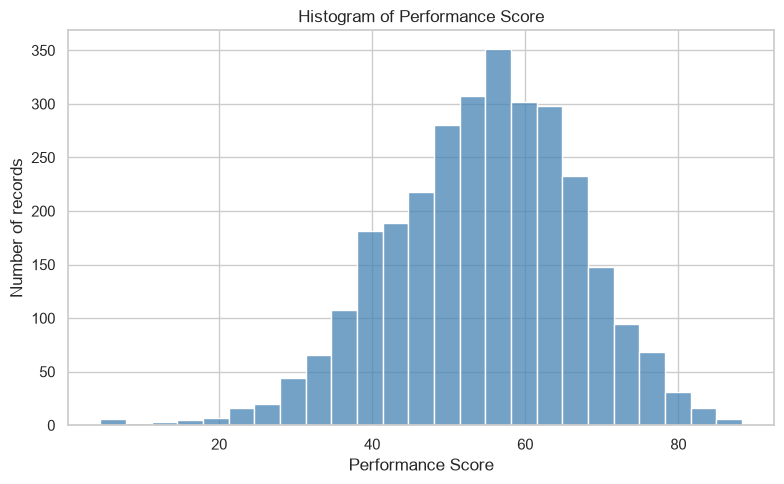

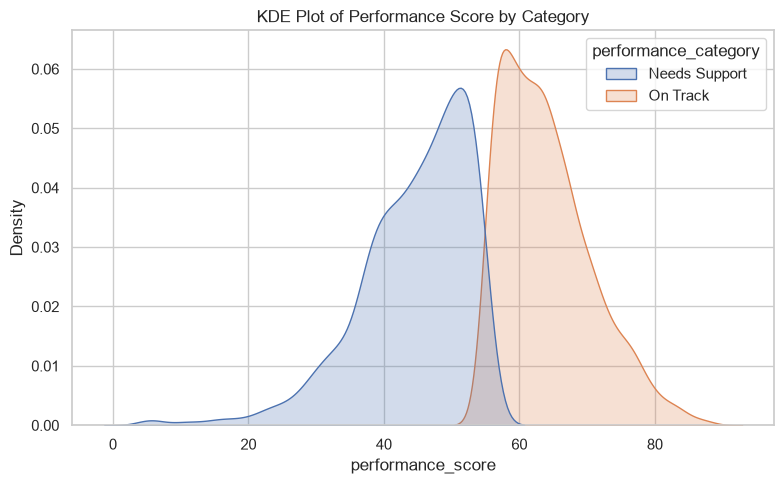

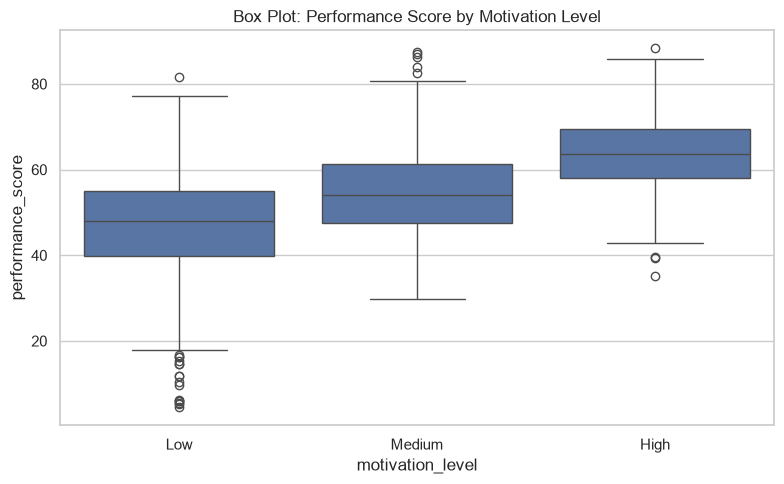

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df["performance_score"], bins=25, color="steelblue", ax=ax)
ax.set_title("Histogram of Performance Score")
ax.set_xlabel("Performance Score"); ax.set_ylabel("Number of records")
fig.tight_layout(); fig.savefig("charts/1_histogram.png", dpi=120); plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
sns.kdeplot(data=df, x="performance_score", hue="performance_category",
            fill=True, common_norm=False, ax=ax)
ax.set_title("KDE Plot of Performance Score by Category")
fig.tight_layout(); fig.savefig("charts/2_kde.png", dpi=120); plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="motivation_level", y="performance_score",
            order=["Low", "Medium", "High"], ax=ax)
ax.set_title("Box Plot: Performance Score by Motivation Level")
fig.tight_layout(); fig.savefig("charts/3_boxplot.png", dpi=120); plt.show()

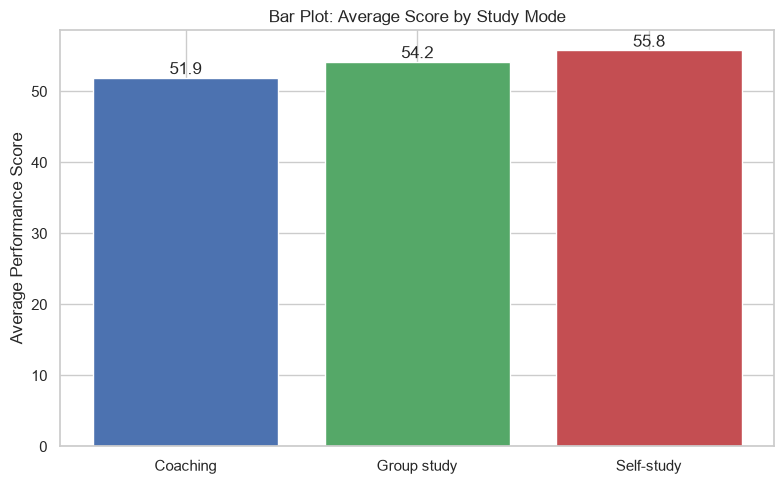

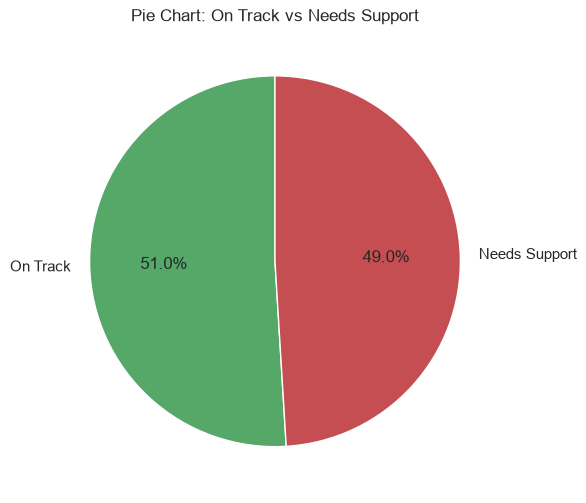

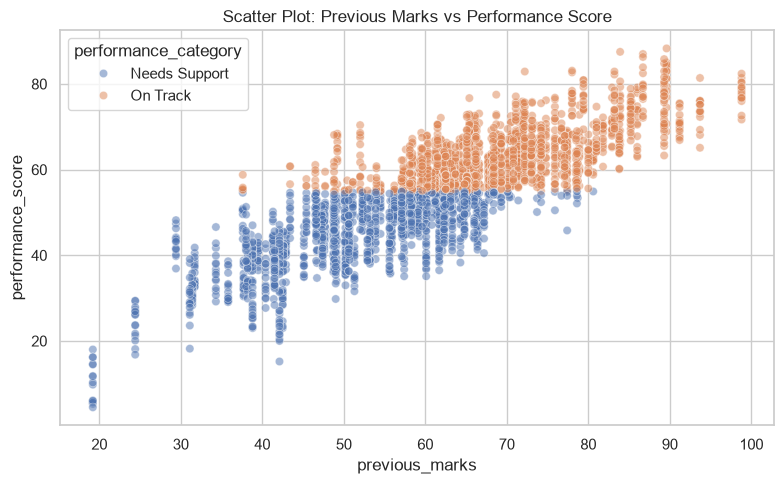

In [7]:
mean_mode = df.groupby("study_mode")["performance_score"].mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(mean_mode.index, mean_mode.values, color=["#4c72b0", "#55a868", "#c44e52"])
for i, v in enumerate(mean_mode.values):
    ax.text(i, v + 0.5, f"{v:.1f}", ha="center")
ax.set_title("Bar Plot: Average Score by Study Mode")
ax.set_ylabel("Average Performance Score")
fig.tight_layout(); fig.savefig("charts/4_bar.png", dpi=120); plt.show()

counts = df["performance_category"].value_counts()
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90,
       colors=["#55a868", "#c44e52"])
ax.set_title("Pie Chart: On Track vs Needs Support")
fig.tight_layout(); fig.savefig("charts/5_pie.png", dpi=120); plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df, x="previous_marks", y="performance_score",
                hue="performance_category", alpha=0.5, ax=ax)
ax.set_title("Scatter Plot: Previous Marks vs Performance Score")
fig.tight_layout(); fig.savefig("charts/6_scatter.png", dpi=120); plt.show()

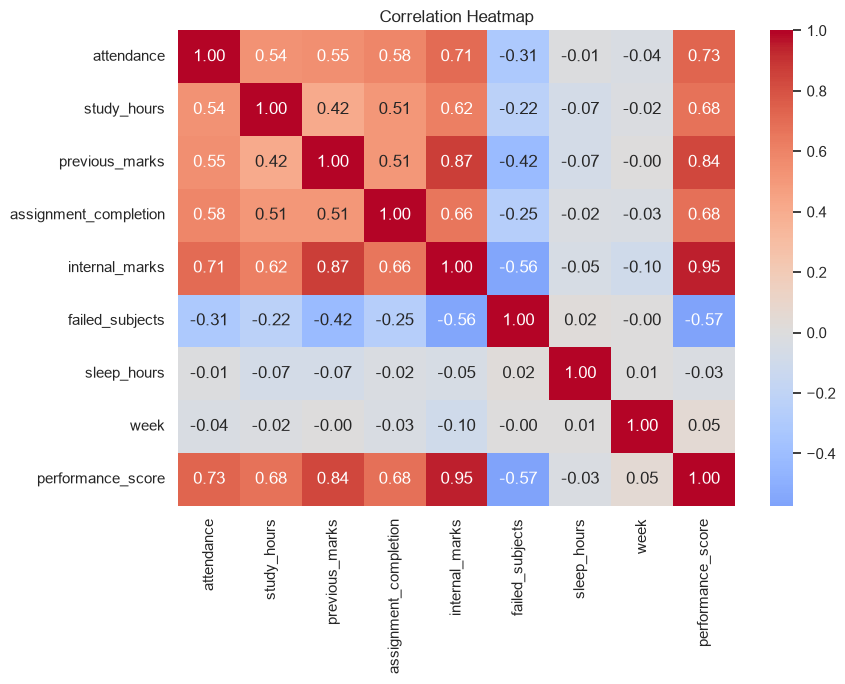

internal_marks           0.95
previous_marks           0.84
attendance               0.73
assignment_completion    0.68
study_hours              0.68
week                     0.05
sleep_hours             -0.03
failed_subjects         -0.57
Name: performance_score, dtype: float64


In [19]:
corr = df[num_cols + ["week", "performance_score"]].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Heatmap")
fig.tight_layout(); fig.savefig("charts/7_heatmap.png", dpi=120); plt.show()

print(corr["performance_score"].drop("performance_score").sort_values(ascending=False).round(2))

In [20]:
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder

enc = df.copy()

# Label Encoding: the target (text -> 0/1)
le = LabelEncoder()
enc["category_encoded"] = le.fit_transform(enc["performance_category"])
print("Label Encoding:", dict(zip(le.classes_, le.transform(le.classes_))))

# Ordinal Encoding: categories that have a natural order
oe = OrdinalEncoder(categories=[["Low", "Medium", "High"],
                                ["1st Year", "2nd Year", "3rd Year"]])
enc[["motivation_encoded", "year_encoded"]] = oe.fit_transform(enc[["motivation_level", "year"]])

# One-Hot Encoding: categories with NO natural order
enc = pd.get_dummies(enc, columns=["study_mode"], prefix="mode", dtype=int)

print("\nOrdinal Encoding sample:")
print(enc[["motivation_level", "motivation_encoded", "year", "year_encoded"]].drop_duplicates().head(6))
print("\nOne-Hot columns created:", [c for c in enc.columns if c.startswith("mode_")])

Label Encoding: {'Needs Support': np.int64(0), 'On Track': np.int64(1)}

Ordinal Encoding sample:
    motivation_level  motivation_encoded      year  year_encoded
0             Medium                 1.0  3rd Year           2.0
15            Medium                 1.0  2nd Year           1.0
30              High                 2.0  3rd Year           2.0
37               Low                 0.0  3rd Year           2.0
105              Low                 0.0  1st Year           0.0
120             High                 2.0  1st Year           0.0

One-Hot columns created: ['mode_Coaching', 'mode_Group study', 'mode_Self-study']


Accuracy: 0.9117
               precision    recall  f1-score   support

Needs Support       0.91      0.91      0.91       299
     On Track       0.91      0.91      0.91       301

     accuracy                           0.91       600
    macro avg       0.91      0.91      0.91       600
 weighted avg       0.91      0.91      0.91       600



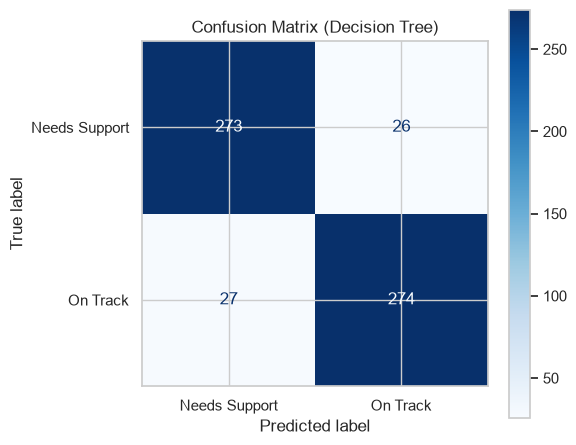

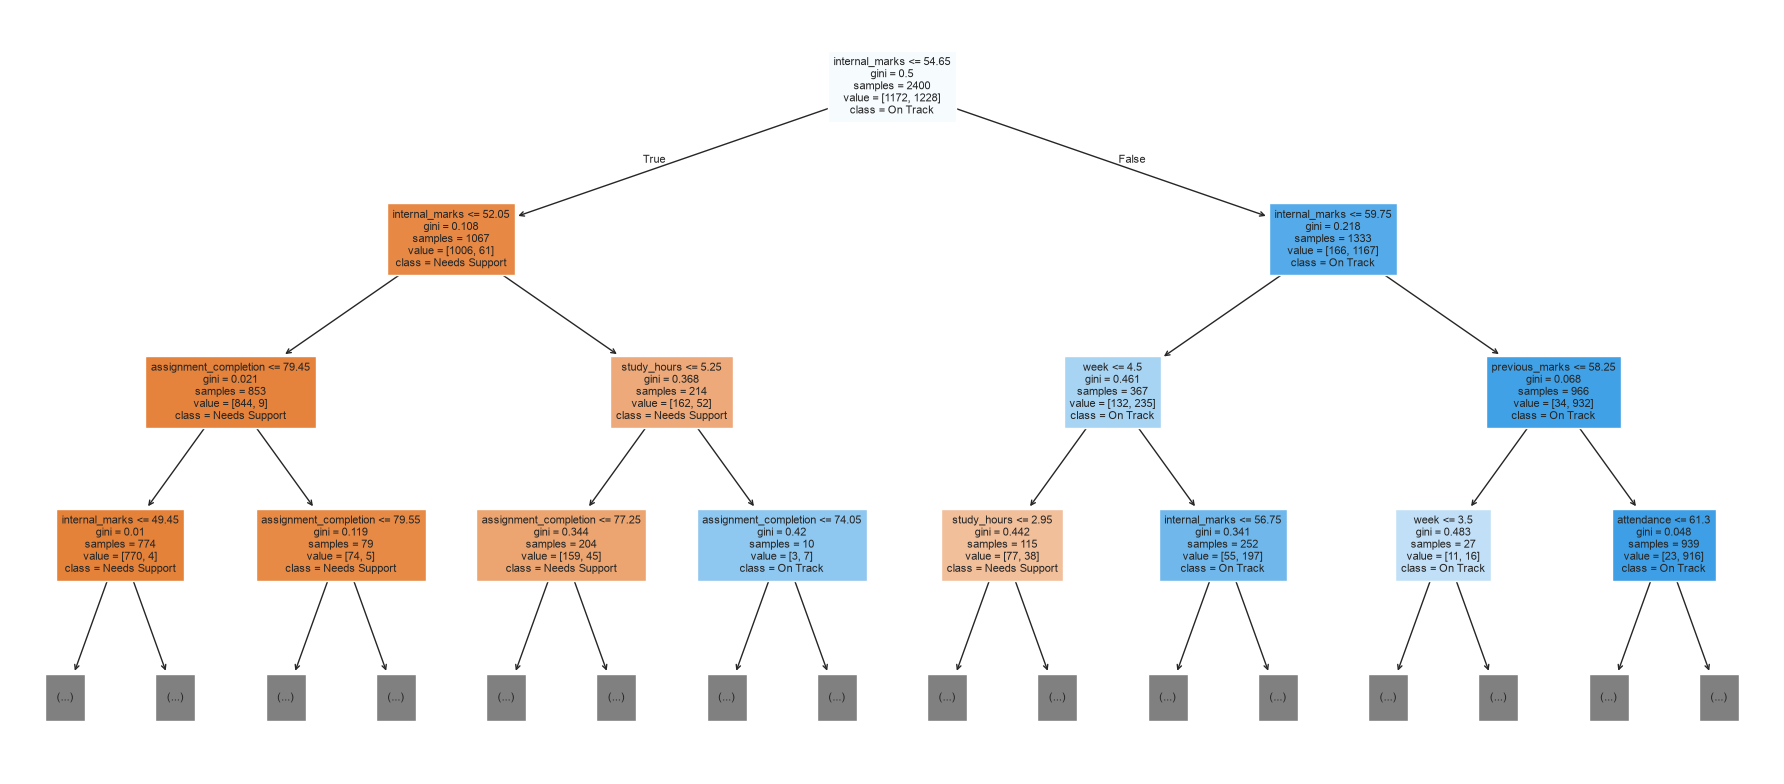

Saved model/decision_tree.joblib and model/decision_tree_metrics.json


In [21]:
import json, joblib
from sklearn.model_selection import GroupShuffleSplit
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

FEATURES = ["week", "attendance", "study_hours", "previous_marks", "assignment_completion",
            "internal_marks", "failed_subjects", "sleep_hours",
            "motivation_encoded", "year_encoded"] + [c for c in enc.columns if c.startswith("mode_")]
X, y = enc[FEATURES], enc["category_encoded"]

# 80:20 split by student (performance_score is NOT a feature, or the answer would leak)
train_idx, test_idx = next(GroupShuffleSplit(test_size=0.2, random_state=42)
                           .split(X, y, groups=enc["student_id"]))
dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt.fit(X.iloc[train_idx], y.iloc[train_idx])

pred = dt.predict(X.iloc[test_idx])
names = list(le.classes_)
acc = accuracy_score(y.iloc[test_idx], pred)
print("Accuracy:", round(acc, 4))
print(classification_report(y.iloc[test_idx], pred, target_names=names))

cm = confusion_matrix(y.iloc[test_idx], pred)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=names).plot(cmap="Blues", ax=ax)
ax.set_title("Confusion Matrix (Decision Tree)")
fig.tight_layout(); fig.savefig("charts/8_confusion_matrix.png", dpi=120); plt.show()

fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(dt, feature_names=FEATURES, class_names=names, filled=True, max_depth=3, fontsize=8, ax=ax)
fig.tight_layout(); fig.savefig("charts/9_decision_tree.png", dpi=120); plt.show()

joblib.dump(dt, "model/decision_tree.joblib")
rep = classification_report(y.iloc[test_idx], pred, target_names=names, output_dict=True)
with open("model/decision_tree_metrics.json", "w") as f:
    json.dump({"accuracy": float(acc), "report": rep, "confusion_matrix": cm.tolist(),
               "classes": names, "n_train": int(len(train_idx)), "n_test": int(len(test_idx)),
               "feature_importance": {k: float(v) for k, v in zip(FEATURES, dt.feature_importances_)}},
              f, indent=2)
print("Saved model/decision_tree.joblib and model/decision_tree_metrics.json")

In [22]:
os.makedirs("pages", exist_ok=True)

In [23]:
%%writefile pages/1_Data_Analysis.py
import json
from pathlib import Path

import pandas as pd
import streamlit as st

BASE = Path(__file__).parent.parent
CHARTS = BASE / "charts"
METRICS = BASE / "model" / "decision_tree_metrics.json"
CLEANED = BASE / "data" / "student_cleaned.csv"

st.set_page_config(page_title="Data Analysis", page_icon="📊", layout="centered")
st.title("📊 Data Analysis and Decision Tree")
st.write("Exploratory analysis of the (synthetic) student dataset, and a Decision Tree classifier "
         "that predicts **On Track** or **Needs Support**.")

tab_data, tab_charts, tab_tree = st.tabs(["🧹 Data and Cleaning", "📈 Charts", "🌳 Decision Tree"])

with tab_data:
    st.subheader("Cleaned dataset")
    if CLEANED.exists():
        df = pd.read_csv(CLEANED)
        st.write(f"{df.shape[0]} rows and {df.shape[1]} columns after cleaning.")
        st.dataframe(df.head(20))
        st.dataframe(df.describe().round(2))
    else:
        st.warning("data/student_cleaned.csv not found. Run the cleaning cell (Cell E) in the notebook.")
    st.markdown("**Cleaning steps performed:** removed duplicate rows, fixed inconsistent text "
                "(spaces and capital letters), marked impossible values as missing, filled missing "
                "numbers with the median and missing categories with the most common value.")
    st.markdown("**Encoding used:** Label Encoding for the target (On Track / Needs Support), "
                "Ordinal Encoding for motivation level and year (they have a natural order), and "
                "One-Hot Encoding for study mode (no natural order).")

with tab_charts:
    charts = [
        ("1_histogram.png", "Histogram: how performance scores are spread"),
        ("2_kde.png", "KDE plot: smooth distribution of scores for each category"),
        ("3_boxplot.png", "Box plot: score by motivation level"),
        ("4_bar.png", "Bar plot: average score by study mode"),
        ("5_pie.png", "Pie chart: share of On Track and Needs Support records"),
        ("6_scatter.png", "Scatter plot: previous marks vs performance score"),
        ("7_heatmap.png", "Correlation heatmap"),
    ]
    found = False
    for file, caption in charts:
        if (CHARTS / file).exists():
            found = True
            st.image(str(CHARTS / file), caption=caption)
    if not found:
        st.warning("No charts found. Run Cells F, G and H in the notebook first.")

with tab_tree:
    if METRICS.exists():
        m = json.loads(METRICS.read_text())
        st.write("**Algorithm:** Decision Tree Classifier (Scikit-learn), max depth 5.")
        st.write(f"**Rows:** {m['n_train']} for training, {m['n_test']} for testing (split by student).")
        st.metric("Accuracy", f"{m['accuracy'] * 100:.1f}%")
        st.markdown("**Classification report**")
        rows = []
        for c in m["classes"]:
            r = m["report"][c]
            rows.append({"Class": c, "Precision": round(r["precision"], 3), "Recall": round(r["recall"], 3),
                         "F1-score": round(r["f1-score"], 3), "Support": int(r["support"])})
        st.table(pd.DataFrame(rows))
        st.markdown("**Confusion matrix**")
        if (CHARTS / "8_confusion_matrix.png").exists():
            st.image(str(CHARTS / "8_confusion_matrix.png"))
        if (CHARTS / "9_decision_tree.png").exists():
            st.markdown("**The tree (top 3 levels)**")
            st.image(str(CHARTS / "9_decision_tree.png"))
        st.markdown("**Feature importance**")
        st.bar_chart(pd.Series(m["feature_importance"]).sort_values())
        st.caption("Trained on synthetic data. High scores show the tree learned the data's rule, "
                   "not that it would work on real students.")
    else:
        st.warning("model/decision_tree_metrics.json not found. Run Cell J in the notebook first.")

Writing pages/1_Data_Analysis.py
